In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



netflix2022 = pd.read_csv("../content_libraries/netflix2022.csv")
amazon2022 = pd.read_csv("../content_libraries/prime2022.csv")
netflix2023 = pd.read_csv("../content_libraries/netflix2023.csv")
amazon2023 = pd.read_csv("../content_libraries/prime2023.csv")
netflix2026 = pd.read_csv("../content_libraries/netflix2026.csv")
amazon2026 = pd.read_csv("../content_libraries/prime2026.csv")


analysis_data = pd.read_csv("../content_libraries/prices/inflation_adjusted_price.csv")
analysis_data["date"] = pd.to_datetime(analysis_data["date"])

# Count titles with IMDb score >= 7
datasets = {
    ("Netflix", 2022): netflix2022,
    ("Prime Video", 2022): amazon2022,
    ("Netflix", 2023): netflix2023,
    ("Prime Video", 2023): amazon2023,
    ("Netflix", 2026): netflix2026,
    ("Prime Video", 2026): amazon2026
}

title_counts = pd.DataFrame([
    {
        "service": service,
        "year": year,
        "high_rated_titles": (df["imdb_score"] >= 7).sum()
    }
    for (service, year), df in datasets.items()
])

# Select inflation-adjusted prices for the correct months
selected_months = {
    2022: 7,   # July
    2023: 3,   # March
    2026: 1    # January
}

prices = analysis_data[
    analysis_data.apply(
        lambda row: row["date"].month == selected_months[row["year"]],
        axis=1
    )
][["service", "year", "inflation_adjusted_price"]].copy()

# Combine title counts with prices
value_for_money = title_counts.merge(
    prices,
    on=["service", "year"],
    how="left",
    validate="one_to_one"
)

# Calculate high-rated titles per dollar
value_for_money["titles_per_dollar"] = (
    value_for_money["high_rated_titles"]
    / value_for_money["inflation_adjusted_price"]
)

value_for_money = value_for_money.round(2)

display(value_for_money)

,service,year,high_rated_titles,inflation_adjusted_price,titles_per_dollar
0,Netflix,2022,2070,11.36,182.22
1,Prime Video,2022,2202,10.22,215.46
2,Netflix,2023,2207,11.15,197.94
3,Prime Video,2023,2482,10.04,247.21
4,Netflix,2026,2814,20.71,135.88
5,Prime Video,2026,2369,14.48,163.60


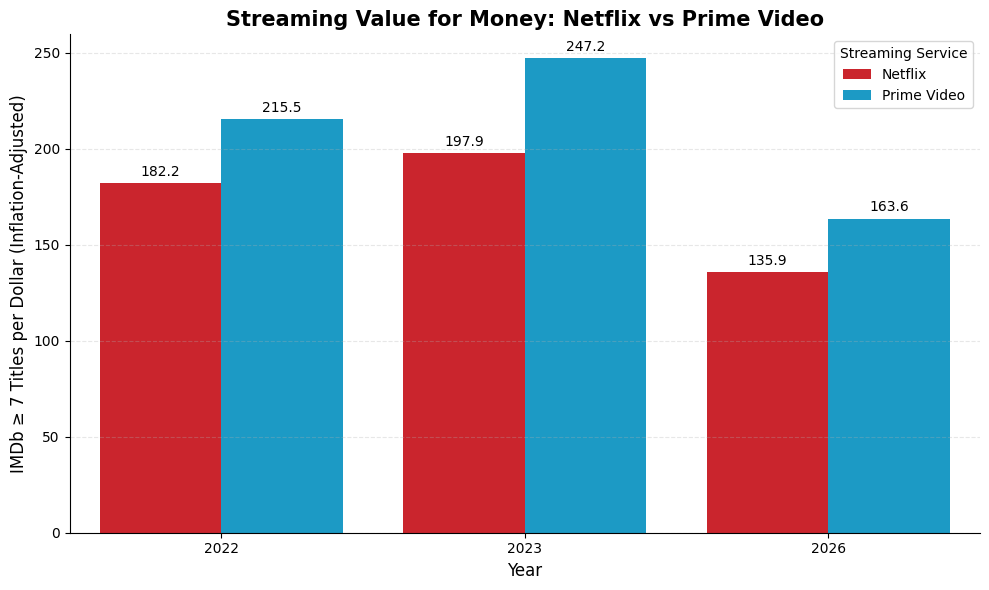

In [14]:
# Plot value for money comparison
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=value_for_money,
    x="year",
    y="titles_per_dollar",
    hue="service",
    palette={
        "Netflix": "#E50914",
        "Prime Video": "#00A8E1"
    }
)

# Add values above each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=3)

plt.title(
    "Streaming Value for Money: Netflix vs Prime Video",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Year", fontsize=12)
plt.ylabel("IMDb ≥ 7 Titles per Dollar (Inflation-Adjusted)", fontsize=12)

plt.legend(title="Streaming Service")
plt.grid(axis="y", linestyle="--", alpha=0.3)

sns.despine()
plt.tight_layout()
plt.show()